In [1]:

!pip install roboflow

!pip install ultralytics



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 15.3 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3━━━━━━━━━━━━━━━━━━━━━ 1/3 [typer]
    Uninstalling typer-0.27.3:m━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [typer]
      Successfully uninstalled typer-0.27.3━━━━━━━━━━━━━━━━━━━ 1/3 [typer]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [roboflow]2/3 [roboflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [2]:

import roboflow
import ultralytics

print("Roboflow installed successfully!")
print("Ultralytics version:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Roboflow installed successfully!
Ultralytics version: 8.4.220


# Step 1: Download the Dataset

In [3]:

from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

# Get API key securely
api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")

# Connect to Roboflow
rf = Roboflow(api_key=api_key)

# Access workspace and project
workspace = rf.workspace("neural-ocean")
project = workspace.project("neural_ocean")

# Select dataset version 3
version = project.version(3)

print("Connected to Roboflow successfully!")
print("Workspace: neural-ocean")
print("Project: neural_ocean")
print("Dataset Version:", 3)


loading Roboflow workspace...
loading Roboflow project...
Connected to Roboflow successfully!
Workspace: neural-ocean
Project: neural_ocean
Dataset Version: 3


In [4]:

# Download Neural Ocean Dataset

dataset = version.download(
    "yolov8",
    location="/kaggle/working/neural_ocean"
)

dataset_path = dataset.location

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)



Extracting Dataset Version Zip to /kaggle/working/neural_ocean in yolov8:: 100%|██████████| 10266/10266 [00:00<00:00, 11369.90it/s]

Dataset downloaded successfully!
Dataset location: /kaggle/working/neural_ocean


# Checking Paths

In [5]:

import os
import yaml

# Check dataset folders
print("Dataset folders:")
for item in os.listdir(dataset_path):
    print("-", item)

# Load dataset configuration
yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("\nDataset Configuration:")
print("Train:", data_config.get("train"))
print("Validation:", data_config.get("val"))
print("Test:", data_config.get("test"))
print("Number of classes:", data_config.get("nc"))
print("Class names:", data_config.get("names"))


Dataset folders:
- valid
- train
- test
- README.dataset.txt
- README.roboflow.txt
- data.yaml

Dataset Configuration:
Train: ../train/images
Validation: ../valid/images
Test: ../test/images
Number of classes: 15
Class names: ['Mask', 'can', 'cellphone', 'electronics', 'gbottle', 'glove', 'metal', 'misc', 'net', 'pbag', 'pbottle', 'plastic', 'rod', 'sunglasses', 'tire']


# Verifing Labels

In [6]:

# Verify image and label directories

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    print(f"\n{split.upper()}")
    print("Images folder exists:", os.path.exists(image_dir))
    print("Labels folder exists:", os.path.exists(label_dir))

    if os.path.exists(image_dir):
        print("Number of images:", len(os.listdir(image_dir)))

    if os.path.exists(label_dir):
        print("Number of label files:", len(os.listdir(label_dir)))



TRAIN
Images folder exists: True
Labels folder exists: True
Number of images: 3626
Number of label files: 3626

VALID
Images folder exists: True
Labels folder exists: True
Number of images: 1000
Number of label files: 1000

TEST
Images folder exists: True
Labels folder exists: True
Number of images: 501
Number of label files: 501


# Verifying Yaml


In [7]:

# Create a corrected dataset YAML file

custom_yaml = {
    "path": dataset_path,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": data_config["nc"],
    "names": data_config["names"]
}

custom_yaml_path = os.path.join(dataset_path, "data_custom.yaml")

with open(custom_yaml_path, "w") as file:
    yaml.safe_dump(custom_yaml, file, sort_keys=False)

print("Custom YAML created successfully!")
print("YAML path:", custom_yaml_path)
print("Classes:", custom_yaml["names"])


Custom YAML created successfully!
YAML path: /kaggle/working/neural_ocean/data_custom.yaml
Classes: ['Mask', 'can', 'cellphone', 'electronics', 'gbottle', 'glove', 'metal', 'misc', 'net', 'pbag', 'pbottle', 'plastic', 'rod', 'sunglasses', 'tire']


## • What the dataset is used for.
a dataset is used to train, validate, and test computer vision models so they learn to recognize and locate target objects or classes in images and video.
## • What classes exist in the dataset.
Classes: ['Mask', 'can', 'cellphone', 'electronics', 'gbottle', 'glove', 'metal', 'misc', 'net', 'pbag', 'pbottle', 'plastic', 'rod', 'sunglasses', 'tire']


# Step 2: Train a Custom YOLO Model

In [8]:

from ultralytics import YOLO

# Load pretrained YOLO11n model
model = YOLO("yolo11n.pt")

print("YOLO11n model loaded successfully!")


YOLO11n model loaded successfully!


In [9]:
results = model.train(
    data=custom_yaml_path,
    epochs=60,
    imgsz=832,
    batch=8,
    optimizer="AdamW",
    lr0=0.001,
    patience=10,
    project="/kaggle/working/neural_ocean_runs",
    name="yolo11n_neural_ocean",
    device=0,
    workers=2,
    plots=True,
    save=True
)


Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/neural_ocean/data_custom.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=832, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_neural_ocean, nbs=64, nms=None, op

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/60      2.36G      1.628      2.585      1.848         15        832: 100% ━━━━━━━━━━━━ 454/454 9.4it/s 48.1s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 7.5it/s 8.4s0.1s
                   all       1000       1891      0.627      0.177      0.156      0.079

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      2.36G      1.616      2.547      1.862          3        832: 100% ━━━━━━━━━━━━ 454/454 9.3it/s 48.8s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 8.6it/s 7.3s0.1s
                   all       1000       1891      0.668      0.162      0.149     0.0835

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      2.36G       1.58      2.385      1.822          9        832: 100% ━━━━━━━━━━━━ 454/454 9.4it/s 48.4s0.1ss
                 Class     Ima

# identify

In [10]:

import os

# Define the training output directory
weights_dir = "/kaggle/working/neural_ocean_runs/yolo11n_neural_ocean/weights"

best_model_path = os.path.join(weights_dir, "best.pt")
last_model_path = os.path.join(weights_dir, "last.pt")

# Check saved weights
print("Best weights exist:", os.path.exists(best_model_path))
print("Last weights exist:", os.path.exists(last_model_path))

if os.path.exists(best_model_path):
    print("Best model size:", round(os.path.getsize(best_model_path) / (1024 * 1024), 2), "MB")

if os.path.exists(last_model_path):
    print("Last model size:", round(os.path.getsize(last_model_path) / (1024 * 1024), 2), "MB")


Best weights exist: True
Last weights exist: True
Best model size: 5.29 MB
Last model size: 5.29 MB


After training, YOLO saves the trained model weights in the weights directory.

Two important files are generated:

best.pt: Contains the model weights that achieved the best validation performance during training.

last.pt: Contains the model weights from the final training epoch.

The best.pt file is usually preferred for final predictions and deployment because it represents the best validation checkpoint.

Saving model weights is important because they allow the trained model to be reused later without repeating the entire training process.

The weights can be loaded into another notebook or application using the Ultralytics YOLO interface.

## 1. Which file should be used for final prediction?
best.pt should be used because it contains the weights that achieved the best validation performance during training.

## 2. Why is saving model weights important?
Saving weights preserves the learned knowledge of the trained model and avoids repeating the training process.

## 3. How can weights be reused later without retraining?
The saved weights can be loaded directly using YOLO("best.pt") in another notebook or application, then used for predictions.

# Step 4: Test the Model on New Images

In [11]:
best_model = YOLO(best_model_path)

print("Trained YOLO model loaded successfully!")
print("Model weights:", best_model_path)
print("Number of classes:", len(best_model.names))
print("Class names:", best_model.names)

Trained YOLO model loaded successfully!
Model weights: /kaggle/working/neural_ocean_runs/yolo11n_neural_ocean/weights/best.pt
Number of classes: 15
Class names: {0: 'Mask', 1: 'can', 2: 'cellphone', 3: 'electronics', 4: 'gbottle', 5: 'glove', 6: 'metal', 7: 'misc', 8: 'net', 9: 'pbag', 10: 'pbottle', 11: 'plastic', 12: 'rod', 13: 'sunglasses', 14: 'tire'}


# Checking Test

In [12]:

import os

test_images_path = "/kaggle/input/datasets/youssefyasser74/wastes-in-ocean/Wastes"

# List image files
image_files = [
    file for file in os.listdir(test_images_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Number of test images:", len(image_files))
print("\nAvailable images:")

for file in image_files:
    print("-", file)


Number of test images: 8

Available images:
- Copy of bottle.jpg
- Copy of phone.jpg
- Copy of waste.jpeg
- Copy of wasteee.jpeg
- copy of mask1.jpg
- copy of mask2.jpg
- copy of waste 2.jpg
- copy of waste with fish.jpg


### In this step, the trained YOLO11n model is tested on eight unseen images related to the dataset classes. This helps evaluate how well the model detects objects in images that were not used during training.

### The model uses a confidence threshold of 0.25 to filter out detections with low confidence. The predicted images are saved separately for visual inspection.

In [13]:
import os

test_images_path = "/kaggle/input/datasets/youssefyasser74/wastes-in-ocean/Wastes"

image_files = [
    "Copy of bottle.jpg",
    "Copy of phone.jpg",
    "Copy of waste.jpeg",
    "Copy of wasteee.jpeg",
    "copy of mask1.jpg",
    "copy of mask2.jpg",
    "copy of waste 2.jpg",
    "copy of waste with fish.jpg"
]

image_paths = [
    os.path.join(test_images_path, file)
    for file in image_files
]

prediction_results = best_model.predict(
    source=image_paths,
    conf=0.25,
    save=True,
    project="/kaggle/working/neural_ocean_predictions",
    name="test_results",
    exist_ok=True
)

print("Prediction completed!")
print("Number of tested images:", len(prediction_results))
print("Results saved in:", prediction_results[0].save_dir)


0: 832x832 1 pbottle, 11.2ms
1: 832x832 1 cellphone, 11.2ms
2: 832x832 5 pbags, 11.2ms
3: 832x832 2 pbags, 11.2ms
4: 832x832 1 Mask, 11.2ms
5: 832x832 1 gbottle, 11.2ms
6: 832x832 3 pbags, 11.2ms
7: 832x832 4 pbags, 11.2ms
Speed: 3.0ms preprocess, 11.2ms inference, 1.0ms postprocess per image at shape (1, 3, 832, 832)
Results saved to /kaggle/working/neural_ocean_predictions/test_results
Prediction completed!
Number of tested images: 8
Results saved in: /kaggle/working/neural_ocean_predictions/test_results


# Visualise

Number of saved prediction images: 8
copy of waste with fish.jpg


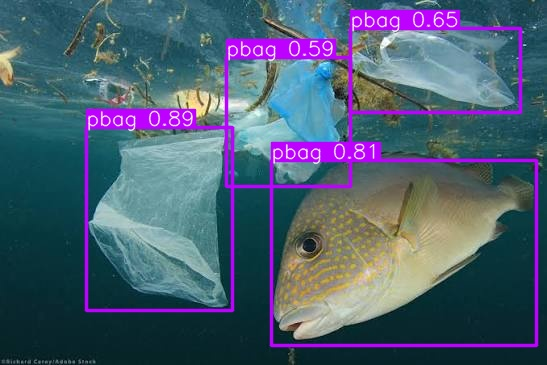

Copy of bottle.jpg


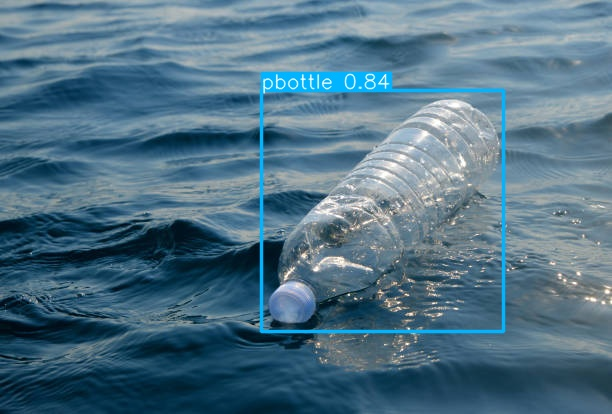

Copy of waste.jpg


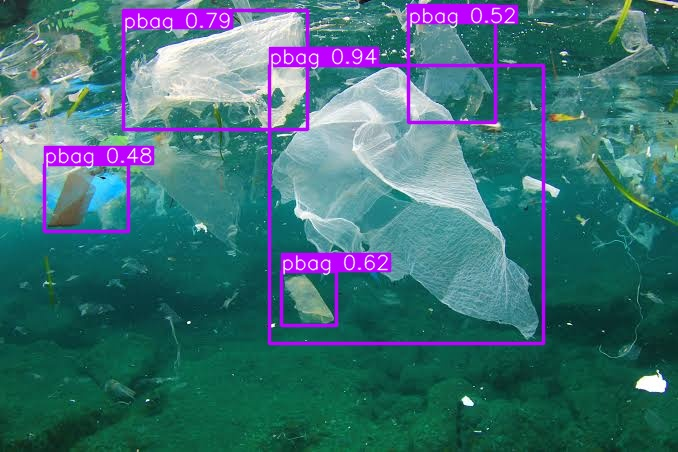

copy of waste 2.jpg


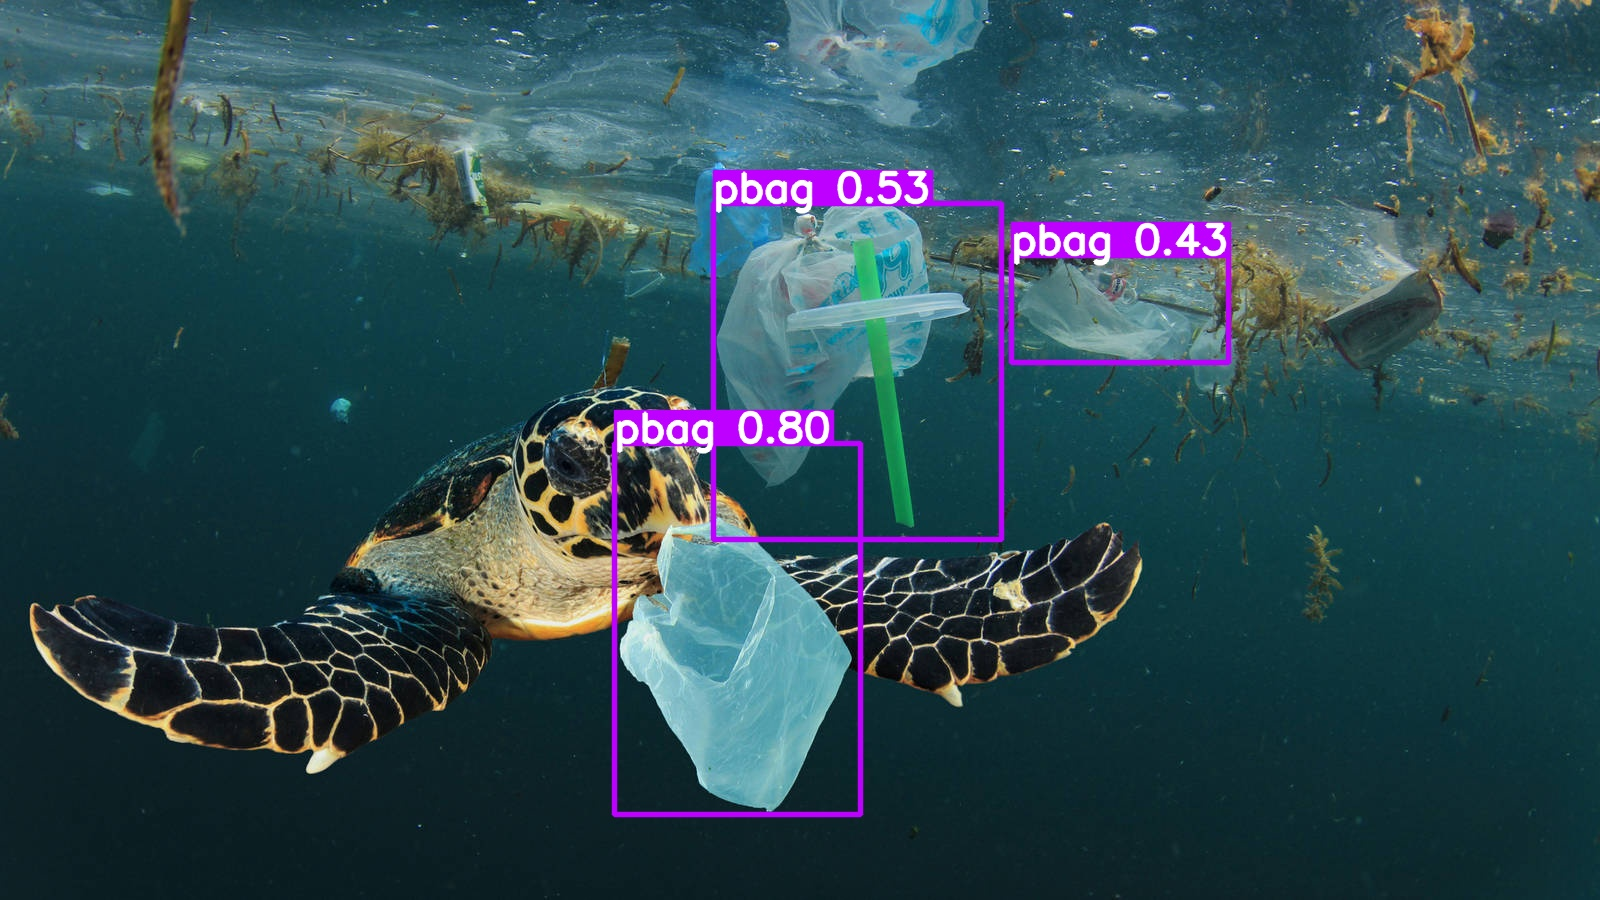

copy of mask2.jpg


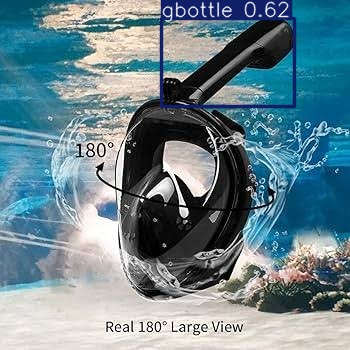

Copy of phone.jpg


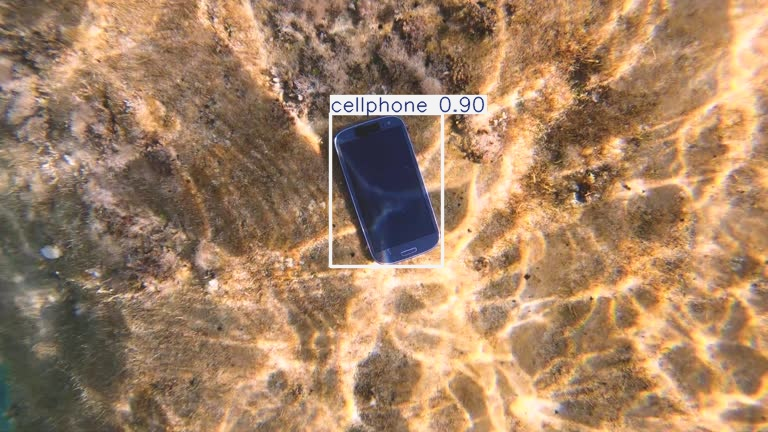

Copy of wasteee.jpg


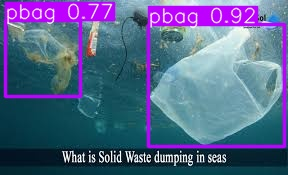

copy of mask1.jpg


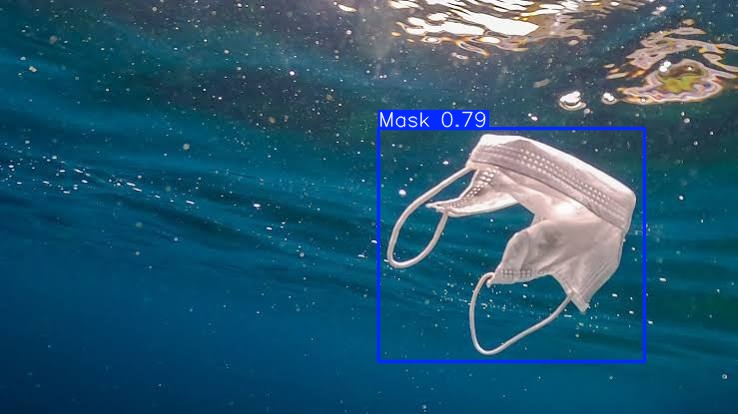

In [14]:
import os
from IPython.display import display, Image

output_path = "/kaggle/working/neural_ocean_predictions/test_results"

result_images = [
    file for file in os.listdir(output_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of saved prediction images:", len(result_images))

for file in result_images:
    print(file)
    display(Image(filename=os.path.join(output_path, file)))

After training, the custom YOLO model was loaded using the saved `best.pt` weights and tested on 8 unseen images.

The test images included examples from the provided image collection, as well as **5 additional external images added manually** to increase the variety of the testing data.

The model was tested on objects related to the Neural Ocean dataset classes, such as bottles, cellphones, masks, and plastic waste.

Predictions were performed using a confidence threshold of 0.25. The model detected the expected objects in most images, including bottles, cellphones, masks, and plastic bags.

One image containing a fish was incorrectly classified as a plastic bag (`pbag`). This is an example of a false positive or misclassification, which can happen when the model encounters an object that does not belong to its trained classes or looks visually similar to a known class.

**Confidence Threshold:** It is the minimum confidence score required for a detection to be displayed. Increasing it may reduce false detections, while decreasing it may allow more detections but also more false positives.

**Why Some Images May Fail:** Detection performance can be affected by image quality, lighting, object size, viewing angle, occlusion, and similarity between different objects. The model may also misclassify objects that are not included in its training classes.

**Importance of Unseen Images:** Testing on images that were not used during training helps evaluate how well the model generalizes to new real-world examples rather than simply memorizing its training data.

# Step 5: Download the Trained Model

In [15]:
import shutil
import os

shutil.copy2(
    best_model_path,
    "/kaggle/working/best.pt"
)

shutil.copy2(
    last_model_path,
    "/kaggle/working/last.pt"
)

print("Model weights copied successfully!")
print("best.pt:", os.path.getsize("/kaggle/working/best.pt") / (1024 * 1024), "MB")
print("last.pt:", os.path.getsize("/kaggle/working/last.pt") / (1024 * 1024), "MB")

Model weights copied successfully!
best.pt: 5.293115615844727 MB
last.pt: 5.293115615844727 MB


After completing the training process, both model weight files were saved successfully:

- **best.pt:** Contains the weights that achieved the best validation performance during training.
- **last.pt:** Contains the weights from the final training epoch.

Both files were copied to the `/kaggle/working/` directory and are approximately 5.29 MB each.

**Which File Is Better for Deployment?**

The `best.pt` file is preferred for final predictions and deployment because it represents the model's best validation performance during training.

**Why Is best.pt Preferred?**

It provides the best-performing saved checkpoint based on validation results, rather than simply representing the final training epoch.

**How Can the Weights Be Reused?**

The saved weights can be loaded later in another notebook or application without repeating the entire training process:

```python
from ultralytics import YOLO

model = YOLO("best.pt")
```

The model can then be used to detect objects in new images or videos.